<h1>Train — ResNet-50</h1>

Trains and evaluates ResNet-50 using the tuned hyperparameters from `ARCH_HYPERPARAMS["resnet50"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 947 | Val: 229 | Test: 567


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["resnet50"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-50: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-50: micro batch = 16, accumulation steps = 6 (effective batch size ≈ 96, tuned value = 96)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with ResNet-50)
# ---------------------------------------------------------
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the Bayesian-optimized step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-50] Using gradient accumulation: 6 micro-batches per optimizer step (effective batch size ≈ micro_batch x 6).


[ResNet-50] Epoch   1/100 | LR: 1.95e-04 | train loss 1.0271 acc 0.572 | val loss 0.8314 acc 0.672 *


[ResNet-50] Epoch   2/100 | LR: 1.95e-04 | train loss 0.8496 acc 0.663 | val loss 0.6397 acc 0.725 *


[ResNet-50] Epoch   3/100 | LR: 1.95e-04 | train loss 0.7787 acc 0.676 | val loss 0.6408 acc 0.681


[ResNet-50] Epoch   4/100 | LR: 1.95e-04 | train loss 0.6643 acc 0.741 | val loss 0.6043 acc 0.747 *


...

[ResNet-50] Epoch  14/100 | LR: 1.95e-05 | train loss 0.3109 acc 0.888 | val loss 0.5633 acc 0.795


[ResNet-50] Epoch  15/100 | LR: 1.95e-05 | train loss 0.3173 acc 0.897 | val loss 0.5714 acc 0.769


[ResNet-50] Epoch  16/100 | LR: 1.95e-05 | train loss 0.2641 acc 0.907 | val loss 0.5724 acc 0.799


[ResNet-50] Epoch  17/100 | LR: 1.95e-05 | train loss 0.2486 acc 0.910 | val loss 0.5946 acc 0.786


[ResNet-50] Epoch  18/100 | LR: 1.95e-05 | train loss 0.2285 acc 0.921 | val loss 0.6247 acc 0.808

[ResNet-50] No val loss improvement for 10 epochs — stopping early at epoch 18.

[ResNet-50] Restored best checkpoint (val loss = 0.5105)


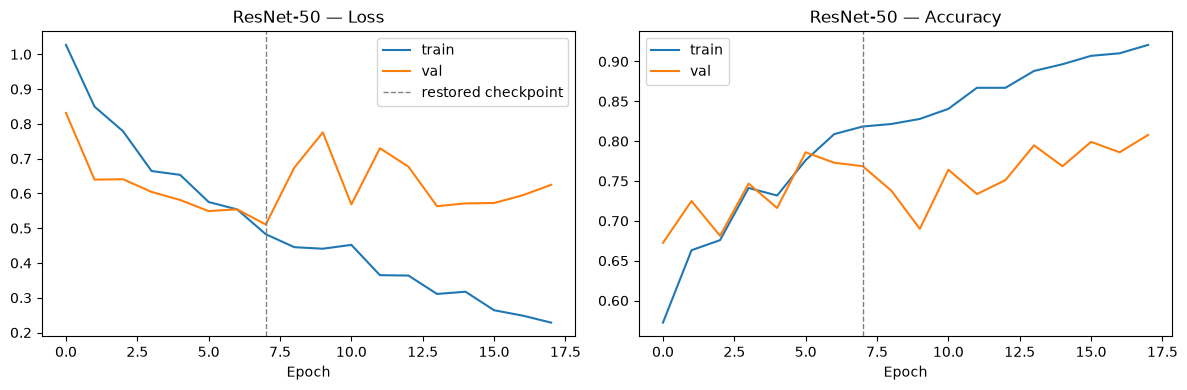

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-50", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-50")

## Evaluate on the test set

[ResNet-50] Test accuracy: 0.815


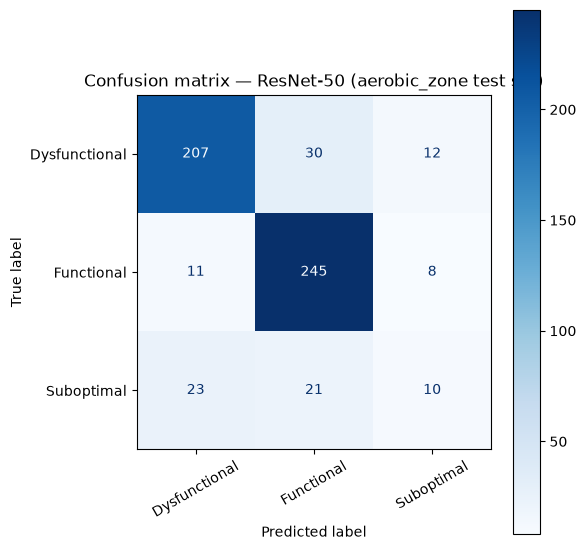

               precision    recall  f1-score   support

Dysfunctional      0.859     0.831     0.845       249
   Functional      0.828     0.928     0.875       264
   Suboptimal      0.333     0.185     0.238        54

     accuracy                          0.815       567
    macro avg      0.673     0.648     0.653       567
 weighted avg      0.794     0.815     0.801       567



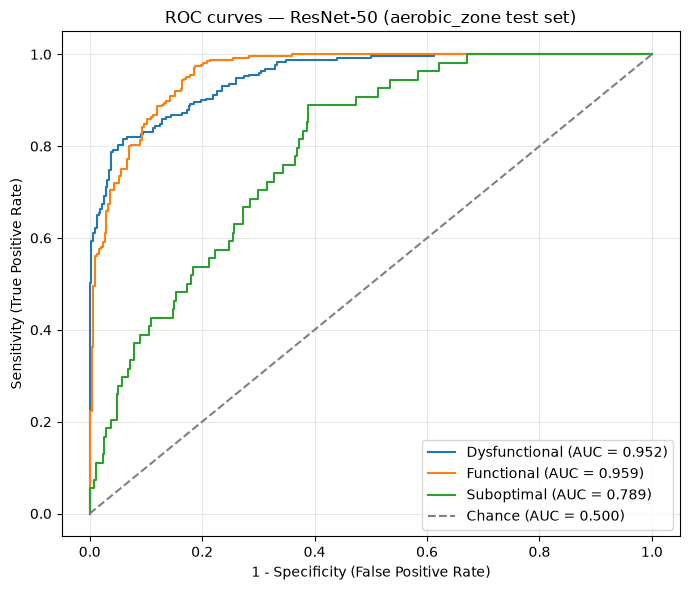

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.952
  Functional     : 0.959
  Suboptimal     : 0.789

Mean AUC (over 3/3 classes with test examples): 0.900


(np.float64(0.8148148148148148),
 {'Dysfunctional': 0.9515293879922204,
  'Functional': 0.958970897089709,
  'Suboptimal': 0.789437585733882})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-50", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("ResNet-50", "resnet50")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet50_chronological.pkl
Saved model weights to ../models/pad/aerobic_zone_resnet50_cnn.pt
